## Pumpkin Pricing

Load up required libraries and dataset. Convert the data to a dataframe containing a subset of the data: 

- Only get pumpkins priced by the bushel
- Convert the date to a month
- Calculate the price to be an average of high and low prices
- Convert the price to reflect the pricing by bushel quantity

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime

pumpkins = pd.read_csv('../data/US-pumpkins.csv')

pumpkins.head()


,City Name,Type,Package,Variety,Sub Variety,Grade,Date,Low Price,High Price,Mostly Low,Mostly High,Origin,Origin District,Item Size,Color,Environment,Unit of Sale,Quality,Condition,Appearance,Storage,Crop,Repack,Trans Mode,Unnamed: 24,Unnamed: 25
0,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,4/29/17,270.0,280.0,270.0,280.0,MARYLAND,NaN,lge,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
1,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,5/6/17,270.0,280.0,270.0,280.0,MARYLAND,NaN,lge,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
2,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,160.0,DELAWARE,NaN,med,ORANGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
3,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,160.0,VIRGINIA,NaN,med,ORANGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
4,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,11/5/16,90.0,100.0,90.0,100.0,MARYLAND,NaN,lge,ORANGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN


In [14]:
pumpkins = pumpkins[pumpkins['Package'].str.contains('bushel', case=True, regex=True)]

columns_to_select = ['Package', 'Variety', 'City Name', 'Low Price', 'High Price', 'Date']
pumpkins = pumpkins.loc[:, columns_to_select]

price = (pumpkins['Low Price'] + pumpkins['High Price']) / 2

month = pd.DatetimeIndex(pumpkins['Date']).month
day_of_year = pd.to_datetime(pumpkins['Date']).apply(lambda dt: (dt-datetime(dt.year,1,1)).days)

new_pumpkins = pd.DataFrame(
    {'Month': month, 
     'DayOfYear' : day_of_year, 
     'Variety': pumpkins['Variety'], 
     'City': pumpkins['City Name'], 
     'Package': pumpkins['Package'], 
     'Low Price': pumpkins['Low Price'],
     'High Price': pumpkins['High Price'], 
     'Price': price})

new_pumpkins.loc[new_pumpkins['Package'].str.contains('1 1/9'), 'Price'] = price/1.1
new_pumpkins.loc[new_pumpkins['Package'].str.contains('1/2'), 'Price'] = price*2

new_pumpkins.head()


/var/folders/n2/7cwgxj_96hq1frcr16zp5lh00000gn/T/ipykernel_66036/2637987050.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  day_of_year = pd.to_datetime(pumpkins['Date']).apply(lambda dt: (dt-datetime(dt.year,1,1)).days)


,Month,DayOfYear,Variety,City,Package,Low Price,High Price,Price
70,9,267,PIE TYPE,BALTIMORE,1 1/9 bushel cartons,15.0,15.0,13.636364
71,9,267,PIE TYPE,BALTIMORE,1 1/9 bushel cartons,18.0,18.0,16.363636
72,10,274,PIE TYPE,BALTIMORE,1 1/9 bushel cartons,18.0,18.0,16.363636
73,10,274,PIE TYPE,BALTIMORE,1 1/9 bushel cartons,17.0,17.0,15.454545
74,10,281,PIE TYPE,BALTIMORE,1 1/9 bushel cartons,15.0,15.0,13.636364


A basic scatterplot reminds us that we only have month data from August through December. We probably need more data to be able to draw conclusions in a linear fashion.

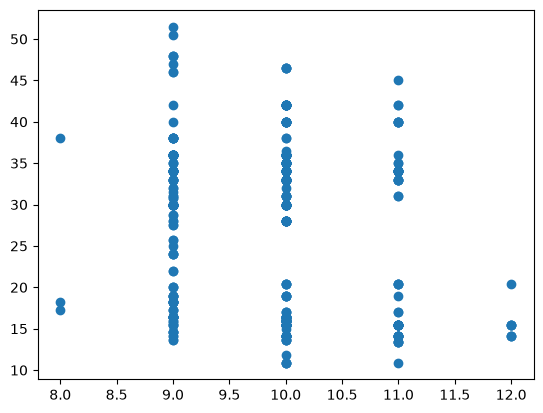

In [15]:
import matplotlib.pyplot as plt
plt.scatter('Month','Price',data=new_pumpkins)

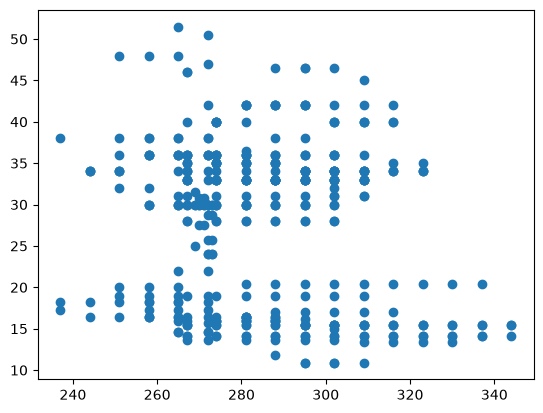

In [16]:

plt.scatter('DayOfYear','Price',data=new_pumpkins)

In [17]:
print(new_pumpkins['Month'].corr(new_pumpkins['Price']))
print(new_pumpkins['DayOfYear'].corr(new_pumpkins['Price']))

-0.1487829355407754
-0.16673322492745402


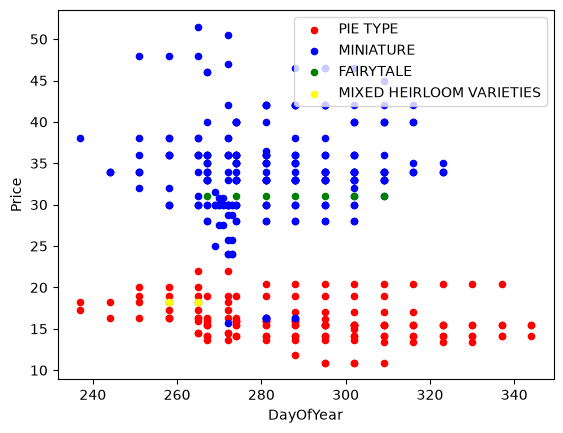

In [18]:
ax=None
colors=['red','blue','green','yellow']
for i, var in enumerate(new_pumpkins['Variety'].unique()):
    df=new_pumpkins[new_pumpkins['Variety']==var]
    ax=df.plot.scatter('DayOfYear','Price',ax=ax,c=colors[i],label=var)

<Axes: xlabel='Variety'>

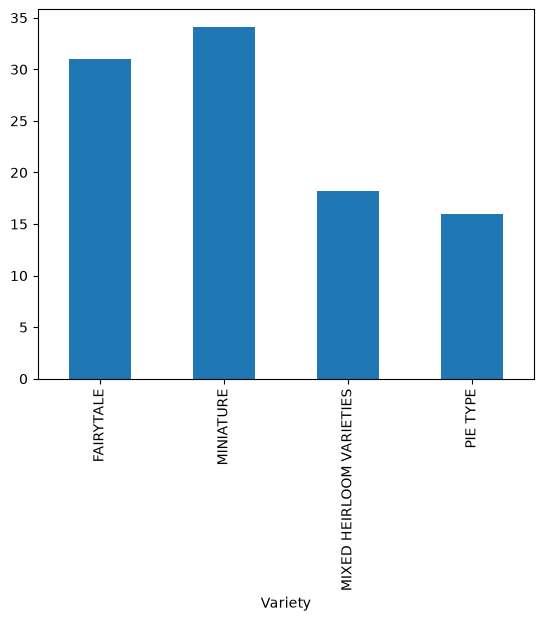

In [19]:
new_pumpkins.groupby('Variety')['Price'].mean().plot(kind='bar')

<Axes: xlabel='DayOfYear', ylabel='Price'>

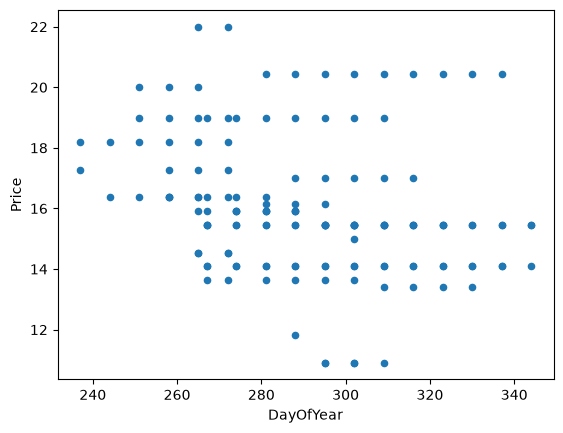

In [20]:
pie_pumpkin=new_pumpkins[new_pumpkins['Variety']=="PIE TYPE"]
pie_pumpkin.plot.scatter('DayOfYear','Price')

In [21]:
pie_pumpkin.dropna(inplace=True)
pie_pumpkin.info()

<class 'pandas.DataFrame'>
Index: 144 entries, 70 to 1630
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Month       144 non-null    int32  
 1   DayOfYear   144 non-null    int64  
 2   Variety     144 non-null    str    
 3   City        144 non-null    str    
 4   Package     144 non-null    str    
 5   Low Price   144 non-null    float64
 6   High Price  144 non-null    float64
 7   Price       144 non-null    float64
dtypes: float64(3), int32(1), int64(1), str(3)
memory usage: 9.6 KB


In [22]:
print(pie_pumpkin['Month'].corr(pie_pumpkin['Price']))
print(pie_pumpkin['DayOfYear'].corr(pie_pumpkin['Price']))

-0.23841413206125708
-0.26691922821973185


In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
X=pie_pumpkin['DayOfYear'].to_numpy().reshape(-1,1)
y=pie_pumpkin['Price']

In [24]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=0)
lin_reg= LinearRegression()
lin_reg.fit(X_train,y_train)
print(lin_reg.coef_)
print(lin_reg.intercept_)

[-0.01751876]
21.133734359909326


In [25]:
pred=lin_reg.predict(X_test)
rmse=np.sqrt(mean_squared_error(y_test,pred))
print(f'RMSE: {rmse:3.3} ({rmse/np.mean(pred)*100:3.3}%)')


RMSE: 2.77 (17.2%)


In [26]:
score=lin_reg.score(X_train,y_train)
print('Model determination:', score)

Model determination: 0.04460606335028361


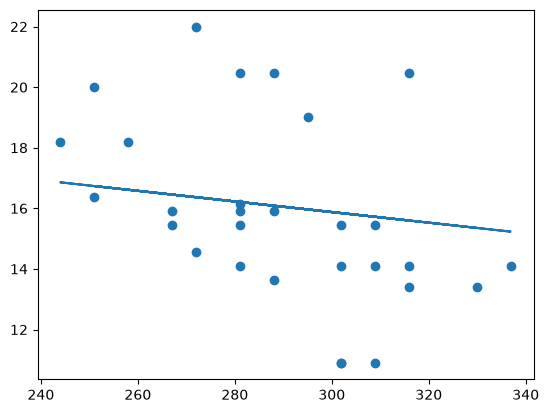

In [27]:
plt.scatter(X_test,y_test)
plt.plot(X_test,pred)

In [28]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
pipeline= make_pipeline(PolynomialFeatures(2),LinearRegression())
pipeline.fit(X_train,y_train)
pred = pipeline.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test,pred))
print(f'RMSE: {rmse:3.3} ({rmse/np.mean(pred)*100:3.3}%)')
score =pipeline.score(X_train,y_train)
print("Model determination:",score)



RMSE: 2.73 (17.0%)
Model determination: 0.07639977655280161


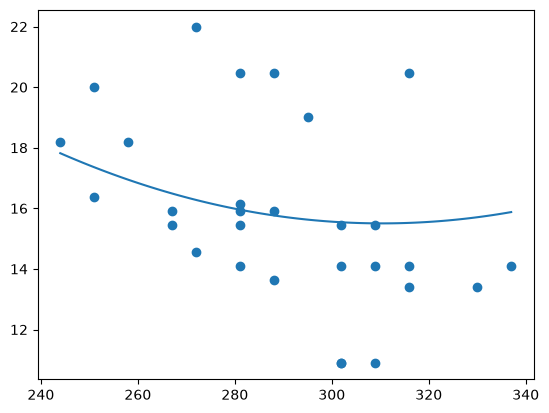

In [29]:
X_range =np.linspace(X_test.min(),X_test.max(),100).reshape(-1,1)
y_range=pipeline.predict(X_range)
plt.scatter(X_test,y_test)
plt.plot(X_range,y_range)

In [26]:
X=pd.get_dummies(new_pumpkins['Variety']) \
    .join(new_pumpkins['Month']) \
    .join(pd.get_dummies(new_pumpkins['City']))\
    .join(pd.get_dummies(new_pumpkins['Package']))
y = new_pumpkins['Price']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=0)
pipeline=make_pipeline(PolynomialFeatures(2),LinearRegression())
pipeline.fit(X_train,y_train)
pred=pipeline.predict(X_test)
rmse=np.sqrt(mean_squared_error(y_test,pred))
print(f'RMSE: {rmse:3.3} ({rmse/pred.mean()*100:3.3}%)')
score =pipeline.score(X_train,y_train)
print('Model determination',score)

RMSE: 2.23 (8.28%)
Model determination 0.9653029999448537


In [31]:
#Assignment part with a california housing dataset
from sklearn.datasets import fetch_california_housing
X,y = fetch_california_housing(return_X_y=True,as_frame=True)
print(X)
print(y)
print(X.columns)

       MedInc  HouseAge  AveRooms  ...  AveOccup  Latitude  Longitude
0      8.3252      41.0  6.984127  ...  2.555556     37.88    -122.23
1      8.3014      21.0  6.238137  ...  2.109842     37.86    -122.22
2      7.2574      52.0  8.288136  ...  2.802260     37.85    -122.24
3      5.6431      52.0  5.817352  ...  2.547945     37.85    -122.25
4      3.8462      52.0  6.281853  ...  2.181467     37.85    -122.25
...       ...       ...       ...  ...       ...       ...        ...
20635  1.5603      25.0  5.045455  ...  2.560606     39.48    -121.09
20636  2.5568      18.0  6.114035  ...  3.122807     39.49    -121.21
20637  1.7000      17.0  5.205543  ...  2.325635     39.43    -121.22
20638  1.8672      18.0  5.329513  ...  2.123209     39.43    -121.32
20639  2.3886      16.0  5.254717  ...  2.616981     39.37    -121.24

[20640 rows x 8 columns]
0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923

In [32]:
print(X['HouseAge'].corr(y))
print(X['MedInc'].corr(y))
print(X['AveRooms'].corr(y))
print(X['AveBedrms'].corr(y))
print(X['AveOccup'].corr(y))


0.10562341249320994
0.6880752079585486
0.15194828974145766
-0.04670051296948688
-0.02373741295613439


In [33]:
Xnew = X['MedInc'].to_numpy().reshape(-1,1)
X_train,X_test,y_train,y_test= train_test_split(Xnew,y,test_size=0.2,random_state=0)
linear_reg=LinearRegression()
linear_reg.fit(X_train,y_train)
print(linear_reg.coef_)


[0.42032178]


In [38]:
pred=linear_reg.predict(X_test)
rmse =np.sqrt(mean_squared_error(y_test,pred))
print(f'RMSE: {rmse:3.3} ({rmse/np.mean(pred)*100:3.3}%)')

RMSE: 0.849 (41.2%)


In [39]:
score=linear_reg.score(X_train,y_train)
print("Model determination",score)

Model determination 0.47991412719941506


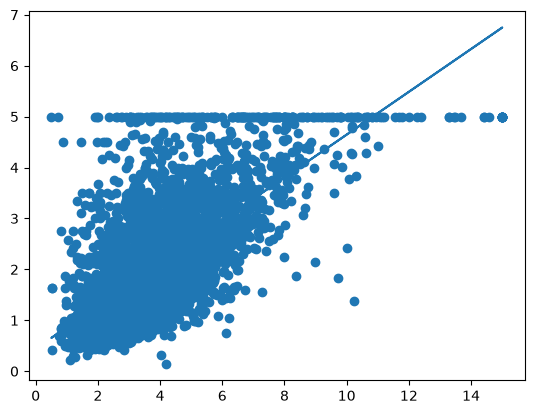

In [40]:
plt.scatter(X_test,y_test)
plt.plot(X_test,pred)

In [41]:
pipeline=make_pipeline(PolynomialFeatures(2),LinearRegression())
pipeline.fit(X_train,y_train)
pred=pipeline.predict(X_test)
rmse =np.sqrt(mean_squared_error(y_test,pred))
print(f'RMSE: {rmse:3.3} ({rmse/np.mean(pred)*100:3.3}%)')


RMSE: 0.847 (41.1%)


In [42]:
score =pipeline.score(X_train,y_train)
print('Model determination',score)

Model determination 0.4848321859601048


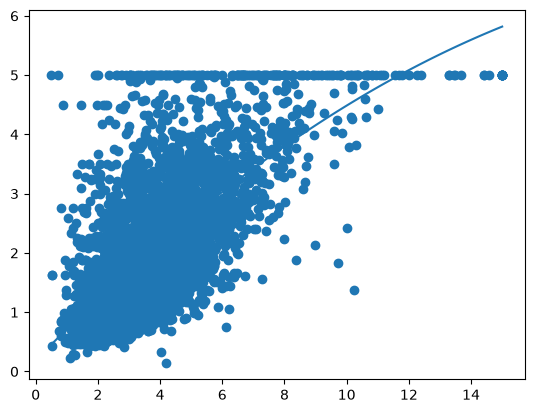

In [43]:
X_range =np.linspace(X_test.min(),X_test.max(),100).reshape(-1,1)
y_range=pipeline.predict(X_range)
plt.scatter(X_test,y_test)
plt.plot(X_range,y_range)